# Sales Prediction from Advertising Spend
**Oasis Infobyte SIP — Data Science Task 5** · Steven Manuel Rios

Dataset: the classic `Advertising.csv` from *An Introduction to Statistical Learning*: 200 markets, with TV, Radio and Newspaper budgets (thousand $) and Sales (thousand units).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
df = pd.read_csv("data/Advertising.csv", index_col=0)
df.columns = ["TV", "Radio", "Newspaper", "Sales"]
print("Shape:", df.shape); print("Nulls:\n", df.isnull().sum()); df.describe()

Shape: (200, 4)
Nulls:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


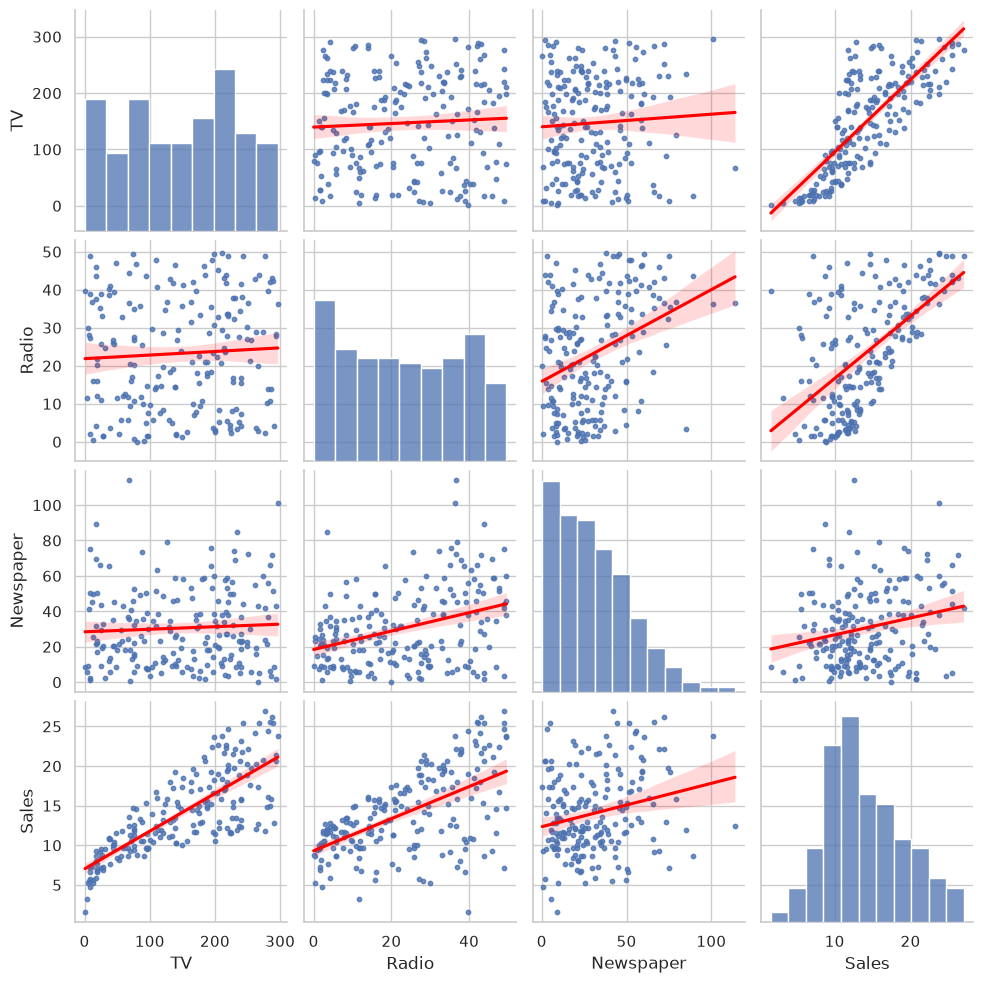

In [3]:
sns.pairplot(df, kind="reg", plot_kws={"line_kws": {"color": "red"}, "scatter_kws": {"s": 10}})
plt.savefig("screenshots/pairplot.png", dpi=90); plt.show()

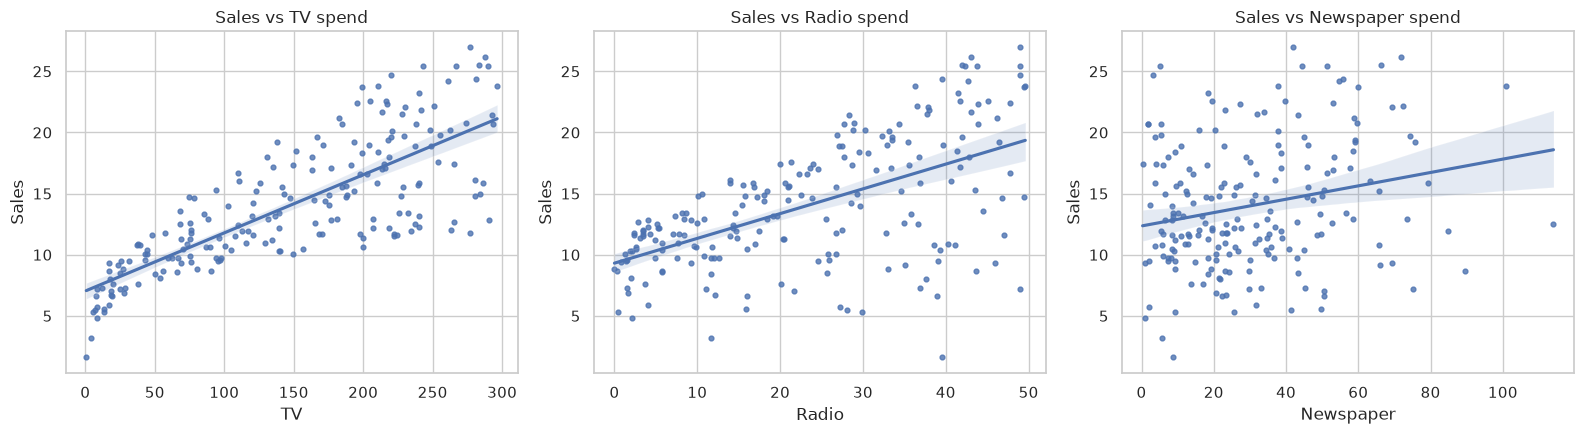

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, ["TV", "Radio", "Newspaper"]):
    sns.regplot(data=df, x=c, y="Sales", ax=a, scatter_kws={"s": 12}); a.set_title(f"Sales vs {c} spend")
save("scatter_channels")

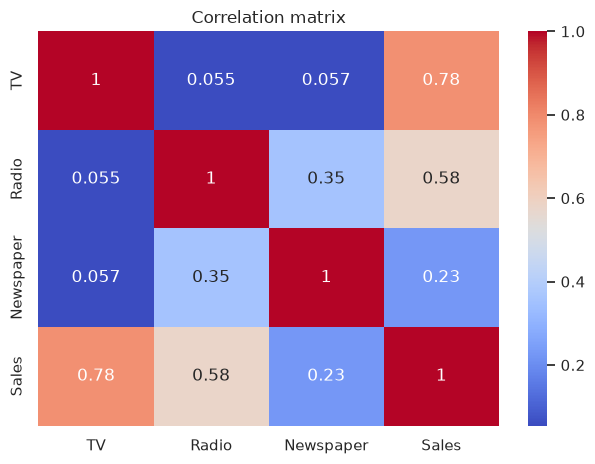

In [5]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm"); plt.title("Correlation matrix"); save("correlation")

**Observation:** TV has the strongest correlation with Sales (r ≈ 0.78), then Radio (≈ 0.58). Newspaper is weak (≈ 0.23), and part of that comes from its correlation with Radio (≈ 0.35).

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
X, y = df[["TV", "Radio", "Newspaper"]], df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
models = {"Linear Regression (baseline)": LinearRegression(),
          "Polynomial Regression (deg 2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
          "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42)}
rows, preds = [], {}
for n, m in models.items():
    m.fit(X_train, y_train); p = preds[n] = m.predict(X_test)
    rows.append({"Model": n, "MAE": mean_absolute_error(y_test, p), "RMSE": mean_squared_error(y_test, p) ** 0.5, "R2": r2_score(y_test, p)})
res = pd.DataFrame(rows).set_index("Model").sort_values("R2", ascending=False).round(3); res

,MAE,RMSE,R2
Model,,,
Polynomial Regression (deg 2),0.526,0.643,0.987
Random Forest,0.614,0.741,0.983
Linear Regression (baseline),1.461,1.782,0.899


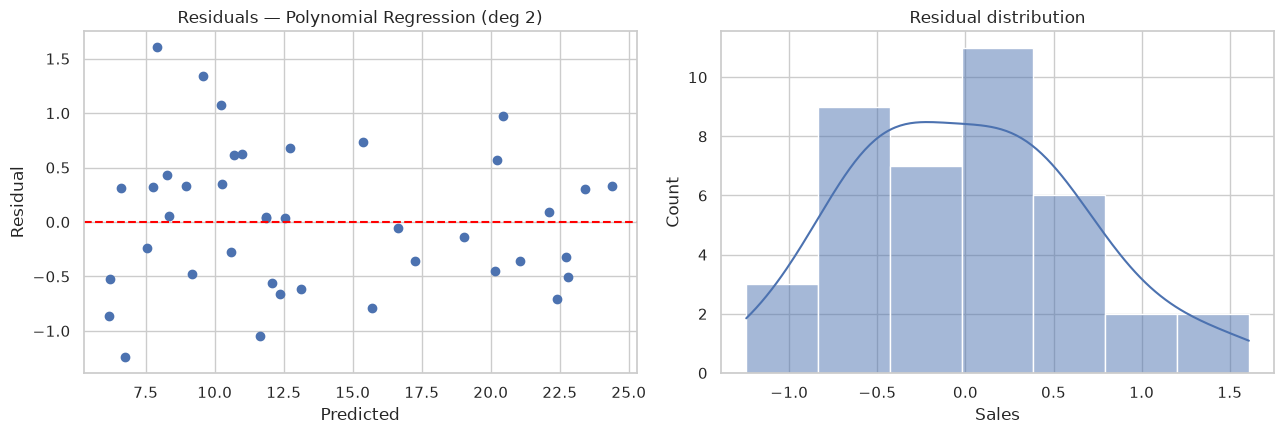

Best model: Polynomial Regression (deg 2)


In [7]:
best = res.index[0]; resid = y_test - preds[best]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(preds[best], resid); ax[0].axhline(0, color="red", ls="--"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual"); ax[0].set_title(f"Residuals — {best}")
sns.histplot(resid, kde=True, ax=ax[1]).set_title("Residual distribution")
save("residuals"); print("Best model:", best)

Linear coefficients (sales units per $1k):
 TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64


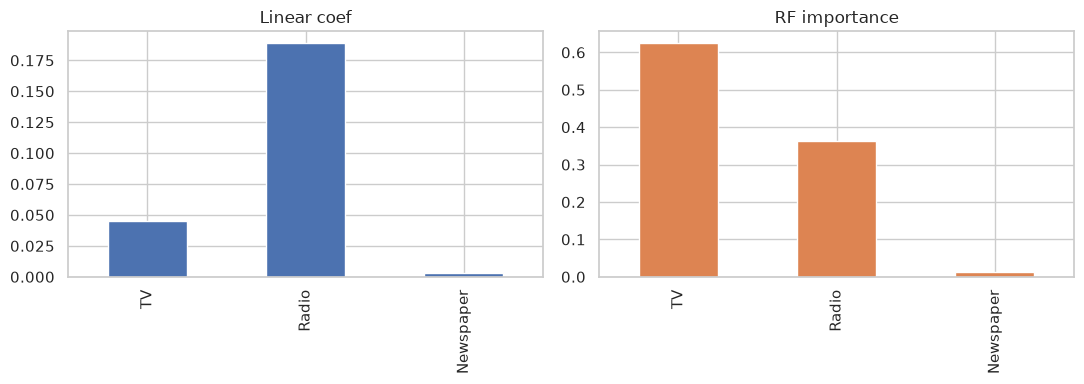

In [8]:
lin = models["Linear Regression (baseline)"]
coef = pd.Series(lin.coef_, index=X.columns); print("Linear coefficients (sales units per $1k):\n", coef.round(4))
rf_imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
pd.DataFrame({"Linear coef": coef, "RF importance": rf_imp}).round(3).plot.bar(subplots=True, layout=(1, 2), figsize=(11, 4), legend=False); save("channel_impact")

## Interpretation
- The **linear baseline** already explains about 90% of the variance, but its residuals curve: it under-predicts when TV and Radio spend are both high. That points to a **TV × Radio interaction (synergy)**.
- The **degree-2 polynomial model** captures this interaction. Its residuals are much smaller and scattered randomly around 0, with no systematic pattern, so it is the best model (see the table above).
- **Channel impact:** **TV** has the largest overall effect on sales (highest Random Forest importance and correlation). **Radio** has the largest effect *per dollar* (its linear coefficient is about 0.19 vs about 0.045 for TV). **Newspaper** has essentially no effect once TV and Radio are accounted for, since its coefficient is about 0.
- **Recommendation:** put the budget into TV and Radio together to exploit the synergy, and cut newspaper spend.